In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path

import pandas as pd
import zarr
import numpy as np

from dotenv import dotenv_values
from scipy.stats import entropy

In [ ]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'region_heterogeneity'
OUTDIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Reference spatial voxel Zarr store
infile = DATADIR / '9_objects' / 'spatial' / 'hypomap3d_spatial_voxel_level.zarr'
store = zarr.open(infile, mode='r')

<Array file:///REDACTED-path/HypoMap3D-data/v0.9/9_objects/spatial/hypomap3d_spatial_voxel_level.zarr/L4/prob shape=(716, 168, 144, 107) dtype=float32>

### Compute entropy per voxel at L4

In [ ]:
# Load probability store for L4
L4_probs = store['L4']['prob'][...]

# Compute entropy per voxel across cell-type probabilities
H = entropy(L4_probs, axis=0, base=2)

In [19]:
# Sanity check: nan values should not change in occurence
np.sum(np.isnan(L4_probs[0])) == np.sum(np.isnan(H))

np.True_

### Compute average entropy per region

In [ ]:
# Load region masks
region_masks = store['region']['region_masks']
region_acronyms = store['region']['acronyms'][:]

array(['TMv', 'int', 'IF', 'PT', 'AAA', 'PVa', 'PVH', 'mfb', 'ACB', 'MT',
       'IMD', 'PVHd', 'LT', 'INC', 'ADP', 'VL', 'AHN', 'nst', 'chpl',
       'och', 'PVi', 'opt', 'PVp', 'MRN', 'V3', 'PVpo', 'PVT', 'RCH',
       'LGv', 'RE', 'RH', 'LHA', 'RL', 'LM', 'RN', 'APN', 'ARH', 'LPO',
       'AV', 'LSr', 'NLOT1', 'RT', 'AVP', 'LSv', 'NLOT2', 'AVPV', 'SCH',
       'BA', 'MA', 'st', 'SF', 'MB', 'SubG', 'BMAa', 'BMAp', 'SI', 'SBPV',
       'sup', 'BST', 'MD', 'PSTN', 'SMT', 'SNc', 'SNr', 'CA1', 'SO',
       'vtd', 'MEA', 'SPFm', 'SPFp', 'CA2', 'fx', 'MEPO', 'CA3', 'alv',
       'STN', 'STR', 'MPN', 'MPO', 'SUM', 'CEAc', 'TH', 'CEAl', 'CEAm',
       'MS', 'CL', 'TRS', 'ND', 'fr', 'NDB', 'CM', 'SPA', 'TU', 'VAL',
       'DG-sg', 'COAa', 'COApm', 'lot', 'CP', 'mp', 'mtg', 'VM', 'VLPO',
       'mtt', 'VMH', 'ml', 'OLF', 'CTXsp', 'VPL', 'VPLpc', 'MMme', 'VPM',
       'VPMpc', 'VTA', 'pm', 'OT', 'PA', 'PAA', 'PAG', 'ZI', 'sm', 'PAL',
       'FF', 'DMH', 'IIn', 'rust', 'aco', 'PCN', 'act', 'cpd'

In [22]:
# Iterate through regions, compute average voxel entropy
dict_region_entropy = {}
for i, acronym in enumerate(region_acronyms):
    voxel_mask = region_masks[i]
    
    avg_entropy = np.nanmean(H[voxel_mask])
    
    dict_region_entropy[acronym] = avg_entropy

In [24]:
# Convert to pandas series
region_entropy = pd.Series(dict_region_entropy, name='H')
region_entropy.index.name='region_acronym'

<Axes: ylabel='region_acronym'>

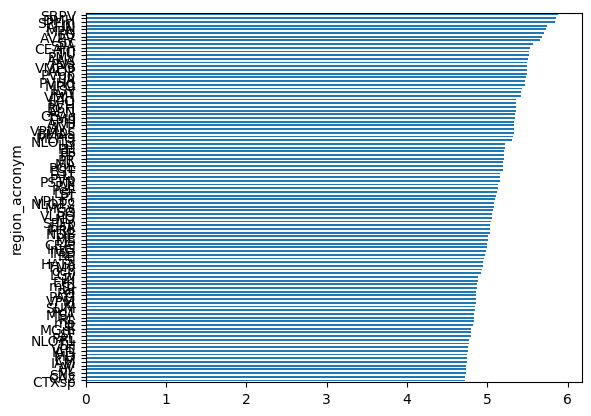

In [30]:
region_entropy.sort_values(ascending=True).tail(100).plot.barh()